Import thư viện và đặt số nút con, threshold

In [14]:
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from sklearn.cluster import Birch as SklearnBirch, KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import warnings
warnings.filterwarnings("ignore")

seed = 42
branching_factor, threshold = 10, 0.5
columns = ["Grocery", "Milk"]

Thêm và đọc dữ liệu

In [15]:
data = pd.read_csv("data/wholesale_customers.csv")
example_data = pd.read_csv("data/minh_hoa_birch.csv")
print("Wholesale customers:", data.shape)
print(data.head())
print("\nMinh họa Birch:", example_data.shape)
print(example_data.head())
print("\nThống kê hai đặc trưng:")
print(data[columns].describe().round(2))

Wholesale customers: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Minh họa Birch: (20, 2)
   Grocery  Milk
0        1     2
1        1     4
2        2     3
3        2     2
4        5     8

Thống kê hai đặc trưng:
        Grocery      Milk
count    440.00    440.00
mean    7951.28   5796.27
std     9503.16   7380.38
min        3.00     55.00
25%     2153.00   1533.00
50%     4755.50   3627.00
75%    10655.75   7190.25
max    92780.00  73498.00


Tiền xử lý dữ liệu

In [16]:
def dem_loi(df):
    so = df[columns].apply(pd.to_numeric, errors="coerce")
    return [int(so.isna().any(axis=1).sum()), int(df.duplicated().sum()), int((so < 0).any(axis=1).sum())]

kiem_tra = pd.DataFrame(
    {"Wholesale": dem_loi(data), "Ví dụ 20 điểm": dem_loi(example_data)},
    index=["Giá trị thiếu hoặc sai định dạng", "Dòng trùng toàn bộ", "Giá trị âm (không hợp lệ)"]
)
display(kiem_tra)
assert kiem_tra.to_numpy().sum() == 0

raw_data = data[columns].to_numpy(float)
example_X = example_data[columns].to_numpy(float)

,Wholesale,Ví dụ 20 điểm
Giá trị thiếu hoặc sai định dạng,0,0
Dòng trùng toàn bộ,0,0
Giá trị âm (không hợp lệ),0,0


Bảng kiểm tra cho thấy cả hai tập dữ liệu không có giá trị thiếu hoặc sai định dạng, không có dòng trùng toàn bộ và không có giá trị âm. Vì vậy không cần bước làm sạch dữ liệu, hai cột Grocery và Milk được giữ nguyên để chuẩn hóa.

In [17]:
class StandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return Z * self.scale_ + self.mean_

Trung bình sau chuẩn hóa: [-0.  0.]
Độ lệch chuẩn sau chuẩn hóa: [1. 1.]


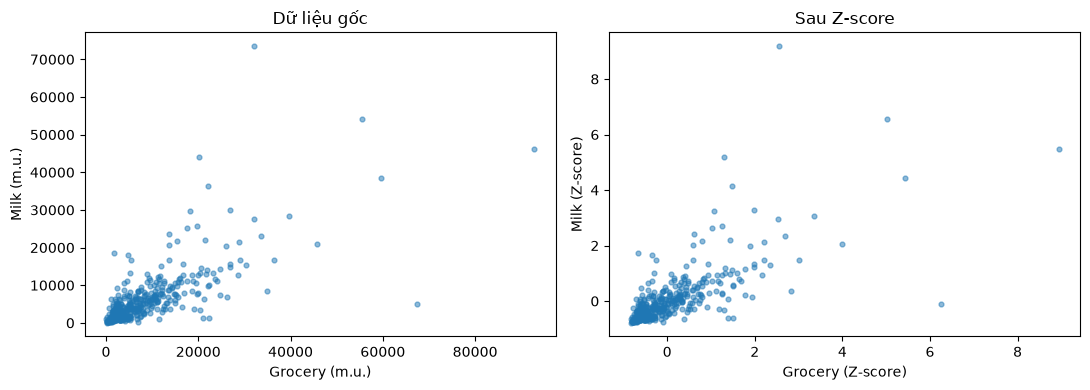

In [18]:
scaler = StandardScaler()
X = scaler.fit_transform(raw_data)
assert np.allclose(X.mean(axis=0), 0) and np.allclose(X.std(axis=0), 1)
print("Trung bình sau chuẩn hóa:", X.mean(axis=0).round(4))
print("Độ lệch chuẩn sau chuẩn hóa:", X.std(axis=0).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(raw_data[:, 0], raw_data[:, 1], s=12, alpha=0.5)
axes[0].set(title="Dữ liệu gốc", xlabel=f"{columns[0]} (m.u.)", ylabel=f"{columns[1]} (m.u.)")
axes[1].scatter(X[:, 0], X[:, 1], s=12, alpha=0.5)
axes[1].set(title="Sau Z-score", xlabel=f"{columns[0]} (Z-score)", ylabel=f"{columns[1]} (Z-score)")
fig.tight_layout()
plt.show()

Cài đặt Birch

Gồm năm lớp: ClusteringFeature, CFEntry, CFNode, CFTree và Birch.
threshold giới hạn bán kính CF lá, branching_factor giới hạn số entry trong mỗi nút.
save_steps chỉ dùng để lưu các bước của ví dụ nhỏ.

In [19]:
class ClusteringFeature:
    def __init__(self, n, ls, ss):
        self.n = n
        self.ls = ls
        self.ss = ss

    def __add__(self, other):
        return ClusteringFeature(self.n + other.n, self.ls + other.ls,
                                 self.ss + other.ss)

    def centroid(self):
        return self.ls / self.n

    def radius(self):
        center = self.centroid()
        radius_squared = self.ss / self.n - np.dot(center, center)
        return float(np.sqrt(max(radius_squared, 0.0)))

    def to_dict(self):
        return {"N": self.n, "LS": self.ls.tolist(), "SS": self.ss,
                "centroid": self.centroid().tolist(), "radius": round(self.radius(), 4)}


class CFEntry:
    def __init__(self, cf, child=None):
        self.cf = cf
        self.child = child


class CFNode:
    def __init__(self, is_leaf, entries=None):
        self.is_leaf = is_leaf
        self.entries = [] if entries is None else entries

    def summary(self):
        total = self.entries[0].cf
        for entry in self.entries[1:]:
            total = total + entry.cf
        return total

Chèn điểm, cập nhật CF cha và tách nút. statistics đếm số nút, số tầng và số CF lá.

In [20]:
class CFTree:
    def __init__(self, threshold=0.5, branching_factor=10, save_steps=False):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.save_steps = save_steps
        self.root = CFNode(is_leaf=True)
        self.history = []

    def insert(self, point):
        point = np.asarray(point, dtype=float)
        cf = ClusteringFeature(1, point.copy(), float(np.dot(point, point)))
        if self.save_steps:
            self.history.append({
                "point": point.tolist(), "action": "new_entry",
                "before_cf": None, "after_cf": cf.to_dict(),
                "candidate_radius": 0.0, "splits": [],
                "before": self.statistics()
            })
        split = self.insert_cf(self.root, cf)
        if split is not None:
            self.root = CFNode(False, [CFEntry(node.summary(), node) for node in split])
            if self.save_steps:
                self.history[-1]["splits"].append("root")
        if self.save_steps:
            self.history[-1]["after"] = self.statistics()

    def insert_cf(self, node, point_cf):
        if not node.entries:
            node.entries.append(CFEntry(point_cf))
            return None
        centers = np.array([e.cf.centroid() for e in node.entries])
        index = int(np.argmin(np.sum((centers - point_cf.centroid()) ** 2, axis=1)))
        closest = node.entries[index]
        if node.is_leaf:
            merged = closest.cf + point_cf
            accepted = merged.radius() <= self.threshold
            if self.save_steps:
                self.history[-1].update({
                    "action": "absorb" if accepted else "new_entry",
                    "before_cf": closest.cf.to_dict(),
                    "after_cf": (merged if accepted else point_cf).to_dict(),
                    "candidate_radius": round(merged.radius(), 4)
                })
            if accepted:
                closest.cf = merged
            else:
                node.entries.append(CFEntry(point_cf))
        else:
            split = self.insert_cf(closest.child, point_cf)
            if split is None:
                closest.cf = closest.child.summary()
            else:
                node.entries[index:index + 1] = [CFEntry(n.summary(), n) for n in split]
        if len(node.entries) > self.branching_factor:
            return self.split_node(node)
        return None

    def split_node(self, node):
        centers = np.array([e.cf.centroid() for e in node.entries])
        a, b = 0, 1
        farthest = -1
        for i in range(len(centers)):
            for j in range(i + 1, len(centers)):
                distance = np.sum((centers[i] - centers[j]) ** 2)
                if distance > farthest:
                    farthest = distance
                    a, b = i, j
        left, right = CFNode(node.is_leaf), CFNode(node.is_leaf)
        for i, entry in enumerate(node.entries):
            if i == a:
                left.entries.append(entry)
            elif i == b:
                right.entries.append(entry)
            elif np.sum((centers[i] - centers[a]) ** 2) <= np.sum((centers[i] - centers[b]) ** 2):
                left.entries.append(entry)
            else:
                right.entries.append(entry)
        if self.save_steps:
            self.history[-1]["splits"].append("leaf" if node.is_leaf else "internal")
        return left, right

    def micro_clusters(self):
        result = []
        def visit(node):
            for entry in node.entries:
                if node.is_leaf:
                    result.append(entry.cf)
                else:
                    visit(entry.child)
        visit(self.root)
        return result

    def statistics(self):
        def visit(node):
            nodes, height = 1, 1
            for entry in node.entries:
                if entry.child is not None:
                    child_nodes, child_height = visit(entry.child)
                    nodes += child_nodes
                    height = max(height, child_height + 1)
            return nodes, height

        nodes, height = visit(self.root)
        return {"N": sum(entry.cf.n for entry in self.root.entries),
                "nodes": nodes, "height": height,
                "micro_clusters": len(self.micro_clusters())}

fit xây cây; mỗi CF ở nút lá là một cụm. predict trả chỉ số tâm CF gần nhất. fit_predict trả nhãn sau khi fit.

In [21]:
class Birch:
    def __init__(self, threshold=0.5, branching_factor=10, save_steps=False):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.save_steps = save_steps

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.tree_ = CFTree(self.threshold, self.branching_factor, self.save_steps)
        for point in X:
            self.tree_.insert(point)
        self.subcluster_centers_ = np.array([
            cf.centroid() for cf in self.tree_.micro_clusters()
        ])
        self.n_clusters_ = len(self.subcluster_centers_)
        self.labels_ = self.predict(X)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        distances = np.zeros((len(X), len(self.subcluster_centers_)))
        for j, center in enumerate(self.subcluster_centers_):
            distances[:, j] = np.sum((X - center) ** 2, axis=1)
        return distances.argmin(axis=1)

    def fit_predict(self, X):
        return self.fit(X).labels_

Minh họa 20 điểm

Đặt threshold=1, branching_factor=2 và giữ giá trị thô để đối chiếu từng bước.
CF_nearest là CF gần nhất được chọn để thử gộp; các cột *_after mô tả CF sau khi hấp thụ hoặc CF mới được tạo nếu không hấp thụ. Bảng thứ hai tổng hợp các bước có tách nút và trạng thái cây trước–sau.

In [22]:
example_model = Birch(threshold=1, branching_factor=2, save_steps=True).fit(example_X)
rows = []
for step, record in enumerate(example_model.tree_.history, 1):
    before = record["before_cf"]
    after = record["after_cf"]
    rows.append({
        "step": step, "point": record["point"], "action": record["action"],
        "CF_nearest": None if before is None else (before["N"], before["LS"], before["SS"]),
        "N_after": after["N"], "LS_after": after["LS"], "SS_after": after["SS"],
        "centroid_after": after["centroid"], "radius_after": after["radius"],
        "candidate_radius": record["candidate_radius"]
    })

result = pd.DataFrame(rows).round(4)
print(result.to_string(index=False))

 step        point    action                CF_nearest  N_after     LS_after  SS_after    centroid_after  radius_after  candidate_radius
    1   [1.0, 2.0] new_entry                      None        1   [1.0, 2.0]       5.0        [1.0, 2.0]        0.0000            0.0000
    2   [1.0, 4.0]    absorb      (1, [1.0, 2.0], 5.0)        2   [2.0, 6.0]      22.0        [1.0, 3.0]        1.0000            1.0000
    3   [2.0, 3.0]    absorb     (2, [2.0, 6.0], 22.0)        3   [4.0, 9.0]      35.0   [1.333333, 3.0]        0.9428            0.9428
    4   [2.0, 2.0]    absorb     (3, [4.0, 9.0], 35.0)        4  [6.0, 11.0]      43.0       [1.5, 2.75]        0.9682            0.9682
    5   [5.0, 8.0] new_entry    (4, [6.0, 11.0], 43.0)        1   [5.0, 8.0]      89.0        [5.0, 8.0]        0.0000            2.6683
    6  [5.0, 10.0]    absorb     (1, [5.0, 8.0], 89.0)        2 [10.0, 18.0]     214.0        [5.0, 9.0]        1.0000            1.0000
    7   [6.0, 9.0]    absorb  (2, [10.0, 

In [23]:
split_rows = []
for step, record in enumerate(example_model.tree_.history, 1):
    if record["splits"]:
        before = record["before"]
        after = record["after"]
        split_rows.append({
            "step": step, "point": record["point"], "splits": ", ".join(record["splits"]),
            "N_before": before["N"], "N_after": after["N"],
            "nodes_before": before["nodes"], "nodes_after": after["nodes"],
            "height_before": before["height"], "height_after": after["height"],
            "n_cf_before": before["micro_clusters"], "n_cf_after": after["micro_clusters"]
        })

split_result = pd.DataFrame(split_rows)
print(split_result.to_string(index=False))
print("\nThống kê cây sau 20 điểm:", example_model.tree_.statistics())

 step        point               splits  N_before  N_after  nodes_before  nodes_after  height_before  height_after  n_cf_before  n_cf_after
    9   [9.0, 3.0]           leaf, root         8        9             1            3              1             2            2           3
   13 [13.0, 10.0] leaf, internal, root        12       13             3            6              2             3            3           4

Thống kê cây sau 20 điểm: {'N': 20, 'nodes': 6, 'height': 3, 'micro_clusters': 5}


Phân cụm Wholesale customers

Dùng toàn bộ 440 dòng đã chuẩn hóa, threshold=0.5 và branching_factor=10.
Số cụm bằng số CF ở nút lá, không đặt trước số cụm và không gom cụm toàn cục.

Thống kê cây: {'N': 440, 'nodes': 4, 'height': 2, 'micro_clusters': 22}


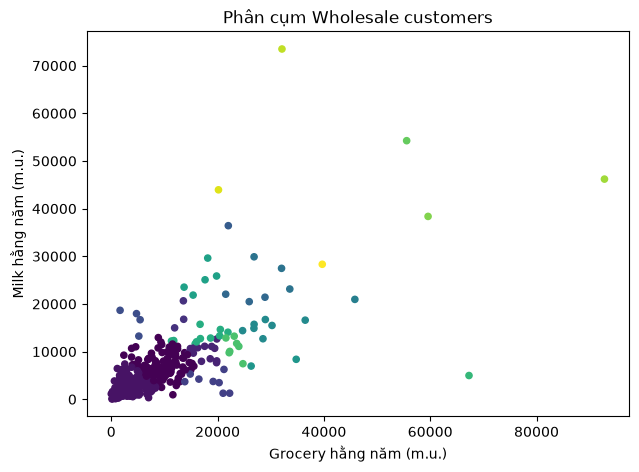

         n_customers  grocery_mean  milk_mean
cluster                                      
1                260       2947.44    2239.75
0                106       9579.98    7016.09
2                 13      17503.62    9936.54
13                10      16991.60   13151.90
4                  8      18643.50    3654.50
10                 7      28953.14   15217.00
15                 7      23077.14   10882.86
12                 5      16941.60   25189.00
5                  4       4256.50   16643.75
3                  3      13039.00   17473.67
8                  3      30828.67   26832.33
7                  3      25469.67   21313.33
11                 2      30554.00    7674.00
9                  1      45828.00   20959.00
6                  1      22019.00   36423.00
14                 1      67298.00    4980.00
16                 1      55571.00   54259.00
17                 1      59598.00   38369.00
18                 1      92780.00   46197.00
19                 1      32114.00

In [24]:
model = Birch(threshold, branching_factor).fit(X)
print("Thống kê cây:", model.tree_.statistics())

plt.figure(figsize=(7, 5))
plt.scatter(raw_data[:, 0], raw_data[:, 1], c=model.labels_, s=20)
plt.xlabel("Grocery hằng năm (m.u.)")
plt.ylabel("Milk hằng năm (m.u.)")
plt.title("Phân cụm Wholesale customers")
plt.show()

cluster_stats = data[columns].copy()
cluster_stats["cluster"] = model.labels_
cluster_stats = cluster_stats.groupby("cluster").agg(
    n_customers=("Grocery", "size"),
    grocery_mean=("Grocery", "mean"),
    milk_mean=("Milk", "mean")
).sort_values(by="n_customers", ascending=False)
print(cluster_stats.round(2))

So sánh với BIRCH thư viện và K-Means

Ba mô hình dùng cùng 440 dòng đã chuẩn hóa trong X theo cùng thứ tự.
BIRCH thư viện đặt n_clusters=None để lấy trực tiếp các cụm CF lá.
K-Means nhận cùng số cụm k bằng số CF lá của BIRCH (22 cụm).
Thực nghiệm lặp lại 100 lần để đo thời gian fit_predict bằng perf_counter() và tính chỉ số Silhouette.

In [ ]:
repeats = 100
k = len(model.subcluster_centers_)

def build_models():
    return [
        ("BIRCH tự viết", Birch(threshold, branching_factor)),
        ("BIRCH sklearn", SklearnBirch(threshold=threshold, branching_factor=branching_factor,
                                       n_clusters=None)),
        ("K-Means", KMeans(n_clusters=k, random_state=42))]

rows = []
trained_models = {}

for name, _ in build_models():
    times_ms = []
    for _ in range(repeats):
        current_model = dict(build_models())[name]
        start = perf_counter()
        labels = current_model.fit_predict(X)
        times_ms.append((perf_counter() - start) * 1000.0)
    trained_models[name] = current_model
    n_clusters = len(np.unique(labels))
    score = silhouette_score(X, labels) if 2 <= n_clusters < len(X) else np.nan
    rows.append({
        "algorithm": name,
        "n_clusters": n_clusters,
        "mean (ms)": round(float(np.mean(times_ms)), 3),
        "median (ms)": round(float(np.median(times_ms)), 3),
        "min (ms)": round(float(np.min(times_ms)), 3),
        "max (ms)": round(float(np.max(times_ms)), 3),
        "tổng tg 100 lần run (s)": round(float(np.sum(times_ms)) / 1000.0, 4),
        "Silhouette": round(float(score), 4)
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

    algorithm  n_clusters  mean (ms)  median (ms)  min (ms)  max (ms)  tổng tg 100 lần run (s)  Silhouette
BIRCH tự viết          22     20.328       19.841    19.274    26.545                   2.0328      0.4745
BIRCH sklearn          22      9.007        8.706     8.444    15.249                   0.9007      0.4745
      K-Means          22      5.064        4.707     3.914    11.628                   0.5064      0.3385


Biểu diễn trực quan phân cụm và biểu đồ Silhouette cho ba mô hình

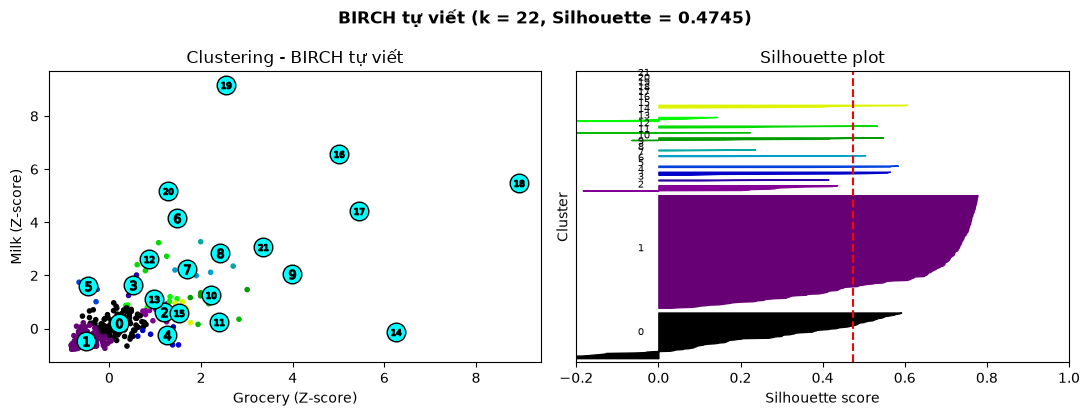

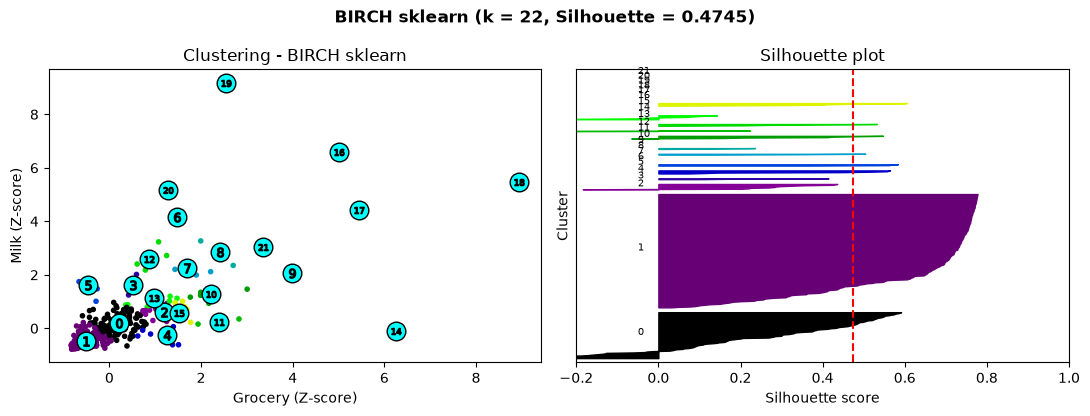

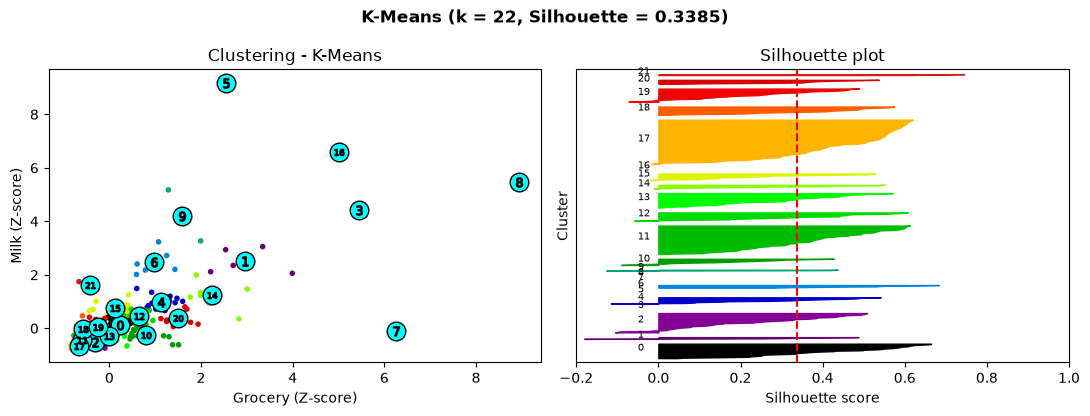

In [ ]:
xmin = -0.2
for model_name, current_model in trained_models.items():
    labels = current_model.labels_
    centroids = (current_model.subcluster_centers_
                 if hasattr(current_model, "subcluster_centers_")
                 else current_model.cluster_centers_)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    colors = cm.nipy_spectral(labels.astype(float) / k)
    ax1.scatter(X[:, 0], X[:, 1], marker=".", c=colors)
    ax1.scatter(centroids[:, 0], centroids[:, 1],
                marker="o", c="cyan", alpha=1, s=180, edgecolor="k")
    
    for i, center in enumerate(centroids):
        ax1.scatter(center[0], center[1], marker=f"${i}$", alpha=1, s=45, edgecolor="k")
    ax1.set(title=f"Clustering - {model_name}", xlabel="Grocery (Z-score)", ylabel="Milk (Z-score)")
    silhouette_avg = silhouette_score(X, labels)
    sample_values = silhouette_samples(X, labels)
    ax2.set_xlim([xmin, 1])
    ax2.set_ylim([0, len(X) + (k + 1) * 10])
    ax2.set(title="Silhouette plot", xlabel="Silhouette score", ylabel="Cluster")
    ax2.axvline(x=silhouette_avg, color="red", linestyle="--")
    ax2.set_yticks([])
    y_lower = 10

    for i in range(k):
        ith_values = sample_values[labels == i]
        ith_values.sort()
        size_i = ith_values.shape[0]
        y_upper = y_lower + size_i
        color = cm.nipy_spectral(float(i) / k)
        ax2.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_values,
                          facecolor=color, edgecolor=color)
        ax2.text(-0.05, y_lower + 0.5 * size_i, str(i), fontsize=7)
        y_lower = y_upper + 10

    fig.suptitle(f"{model_name} (k = {k}, Silhouette = {silhouette_avg:.4f})", fontweight="bold")
    fig.tight_layout()
    plt.show()